# Surrogate Model Set-up

In [55]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from prettytable import PrettyTable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

In [31]:
# Preview the data
DATA_PATH = Path(r"NREL_DEL.csv")
df = pd.read_csv(DATA_PATH)
print(df.head())

         Hs        Tp    Vw_mean    Vw_std        RPM      Pitch           DEL
0  1.248500  4.757716   9.203143  1.749217   9.972552   0.019171  1.460472e+06
1  1.574769  6.303943  11.370682  1.839102  11.694177   1.296207  1.733923e+06
2  0.895745  5.364305  11.460520  1.651695  11.757063   1.184234  1.831648e+06
3  0.638518  7.412787   6.598440  1.438964   8.256958   0.000000  8.610574e+05
4  2.740453  5.828636  15.811478  2.406468  12.093967  10.479204  2.552811e+06


In [32]:
# Load the data into variables
Hs = df["Hs"].values
Tp = df["Tp"].values
Vw_mean = df["Vw_mean"].values
Vw_std = df["Vw_std"].values
RPM = df["RPM"].values
Pitch = df["Pitch"].values
DEL = df["DEL"].values

## Model 1: Linear Regression

In [44]:
# Combine all input variables
X1 = np.column_stack((Hs, Tp, Vw_mean))

# DEL must contain one value per row in X
y1 = np.asarray(DEL).ravel()

print("X shape:", X1.shape)
print("DEL shape:", y1.shape)

# Split into training and testing data
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=100)

# Train the model
model = LinearRegression()
model.fit(X1_train, y1_train)

# Evaluate
y1_pred = model.predict(X1_test)

r2_1 = r2_score(y1_test, y1_pred)
mae_1 = mean_absolute_error(y1_test, y1_pred)
rmse_1 = np.sqrt(mean_squared_error(y1_test, y1_pred))

# Print the coefficients, intercept, and evaluation metrics
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("R²:", r2_score(y1_test, y1_pred))
print("MAE:", mean_absolute_error(y1_test, y1_pred))
print("RMSE:", np.sqrt(mean_squared_error(y1_test, y1_pred)))

X shape: (49791, 3)
DEL shape: (49791,)
Coefficients: [ 70898.91167438 -19057.94652469 121426.47643864]
Intercept: 259068.21525585977
R²: 0.8839279022768547
MAE: 159234.0609208851
RMSE: 215362.19888358423


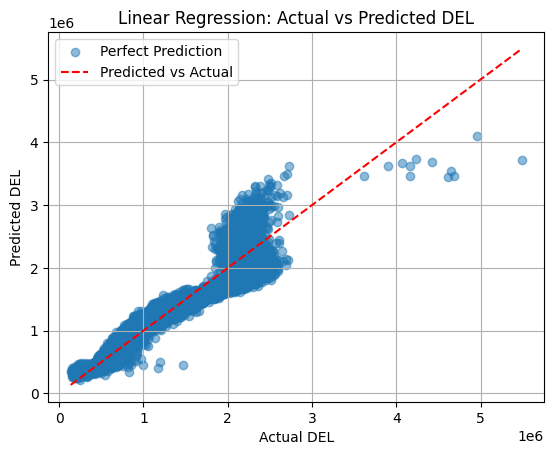

In [45]:
plt.scatter(y1_test, y1_pred, alpha=0.5)

lower = min(y1_test.min(), y1_pred.min())
upper = max(y1_test.max(), y1_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual DEL")
plt.ylabel("Predicted DEL")
plt.title("Linear Regression: Actual vs Predicted DEL")
plt.legend(["Perfect Prediction", "Predicted vs Actual"])
plt.grid(True)
plt.show()

## Model 2: Random Forest

In [46]:
# Features
X2 = np.column_stack((Hs, Tp, Vw_mean))

# Target
y2 = np.asarray(DEL).ravel()


# Split the data
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=100)

# Create and train the model
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

model.fit(X2_train, y2_train)

# Predict
y2_pred = model.predict(X2_test)

r2_2 = r2_score(y2_test, y2_pred)
mae_2 = mean_absolute_error(y2_test, y2_pred)
rmse_2 = np.sqrt(mean_squared_error(y2_test, y2_pred))

# Evaluate
print("R²:", r2_score(y2_test, y2_pred))
print("MAE:", mean_absolute_error(y2_test, y2_pred))
print("RMSE:", np.sqrt(mean_squared_error(y2_test, y2_pred)))

R²: 0.9666461691721902
MAE: 84353.38887820915
RMSE: 115445.8753211119


In [47]:
for name, importance in zip(
    ["Hs", "Tp", "Vw_mean"],
    model.feature_importances_
):
    print(f"{name}: {importance:.4f}")

Hs: 0.0168
Tp: 0.0104
Vw_mean: 0.9728


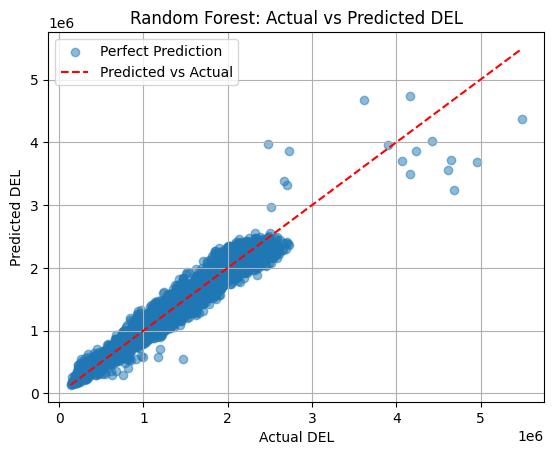

In [48]:
import matplotlib.pyplot as plt

plt.scatter(y2_test, y2_pred, alpha=0.5)

lower = min(y2_test.min(), y2_pred.min())
upper = max(y2_test.max(), y2_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual DEL")
plt.ylabel("Predicted DEL")
plt.title("Random Forest: Actual vs Predicted DEL")
plt.legend(["Perfect Prediction", "Predicted vs Actual"])
plt.grid(True)
plt.show()

## Model 3: Gradient Boosting 

In [49]:
# Features
X3 = np.column_stack((Hs, Tp, Vw_mean))

# Target
y3 = np.asarray(DEL).ravel()


# Split the data
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=100)

# Create and train the model
model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

model.fit(X3_train, y3_train)

# Predict
y3_pred = model.predict(X3_test)

r2_3 = r2_score(y3_test, y3_pred)
mae_3 = mean_absolute_error(y3_test, y3_pred)
rmse_3 = np.sqrt(mean_squared_error(y3_test, y3_pred))

# Evaluate
print("R²:", r2_score(y3_test, y3_pred))
print("MAE:", mean_absolute_error(y3_test, y3_pred))
print("RMSE:", np.sqrt(mean_squared_error(y3_test, y3_pred)))

R²: 0.9695480094695731
MAE: 80506.90195886556
RMSE: 110309.62371832534


In [39]:
for name, importance in zip(
    ["Hs", "Tp", "Vw_mean"],
    model.feature_importances_
):
    print(f"{name}: {importance:.4f}")

Hs: 0.0111
Tp: 0.0006
Vw_mean: 0.9884


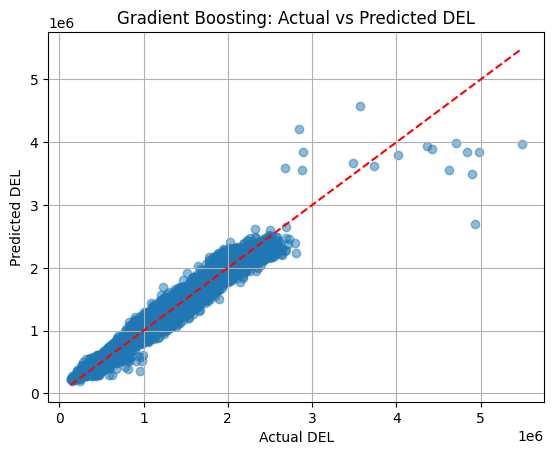

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(y3_test, y3_pred, alpha=0.5)

lower = min(y3_test.min(), y3_pred.min())
upper = max(y3_test.max(), y3_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual DEL")
plt.ylabel("Predicted DEL")
plt.title("Gradient Boosting: Actual vs Predicted DEL")
plt.legend(["Perfect Prediction", "Predicted vs Actual"])
plt.grid(True)
plt.show()

## Model 4: Neural Network

In [50]:
# Features
X4 = np.column_stack((Hs, Tp, Vw_mean))

# Target
y4 = np.asarray(DEL).ravel()

assert X4.shape[0] == y4.shape[0], (
    "The number of DEL values must match the number of input rows."
)

# Split the data
X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4, test_size=0.2, random_state=100)

# Scale features and train the neural network
model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42
    )
)

model.fit(X4_train, y4_train)

# Predict
y4_pred = model.predict(X4_test)

r2_4 = r2_score(y4_test, y4_pred)
mae_4 = mean_absolute_error(y4_test, y4_pred)
rmse_4 = np.sqrt(mean_squared_error(y4_test, y4_pred))

# Evaluate
print("R²:", r2_score(y4_test, y4_pred))
print("MAE:", mean_absolute_error(y4_test, y4_pred))
print("RMSE:", np.sqrt(mean_squared_error(y4_test, y4_pred)))

R²: 0.8835988615461002
MAE: 159401.58165598582
RMSE: 215667.2368179797


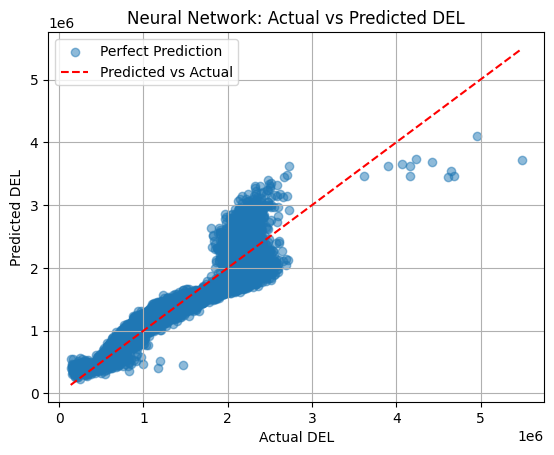

In [41]:
plt.scatter(y4_test, y4_pred, alpha=0.5)

lower = min(y4_test.min(), y4_pred.min())
upper = max(y4_test.max(), y4_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual DEL")
plt.ylabel("Predicted DEL")
plt.title("Neural Network: Actual vs Predicted DEL")
plt.legend(["Perfect Prediction", "Predicted vs Actual"])
plt.grid(True)
plt.show()

## Summary

In [56]:
print("Model Evaluation Results:")
r2_values = [r2_1, r2_2, r2_3, r2_4]
mae_values = [mae_1, mae_2, mae_3, mae_4]
rmse_values = [rmse_1, rmse_2, rmse_3, rmse_4]

results = [
    {"Model": "Linear Regression", "R²": r2_values[0], "MAE": mae_values[0], "RMSE": rmse_values[0]},
    {"Model": "Random Forest", "R²": r2_values[1], "MAE": mae_values[1], "RMSE": rmse_values[1]},
    {"Model": "Gradient Boosting", "R²": r2_values[2], "MAE": mae_values[2], "RMSE": rmse_values[2]},
    {"Model": "Neural Network", "R²": r2_values[3], "MAE": mae_values[3], "RMSE": rmse_values[3]}
]

table = PrettyTable()
table.field_names = ["Model", "R²", "MAE", "RMSE"]

for result in results:
    table.add_row([
        result["Model"],
        f'{result["R²"]:.4f}',
        f'{result["MAE"]:.4f}',
        f'{result["RMSE"]:.4f}'
    ])

print(table)

Model Evaluation Results:
+-------------------+--------+-------------+-------------+
|       Model       |   R²   |     MAE     |     RMSE    |
+-------------------+--------+-------------+-------------+
| Linear Regression | 0.8839 | 159234.0609 | 215362.1989 |
|   Random Forest   | 0.9666 |  84353.3889 | 115445.8753 |
| Gradient Boosting | 0.9695 |  80506.9020 | 110309.6237 |
|   Neural Network  | 0.8836 | 159401.5817 | 215667.2368 |
+-------------------+--------+-------------+-------------+


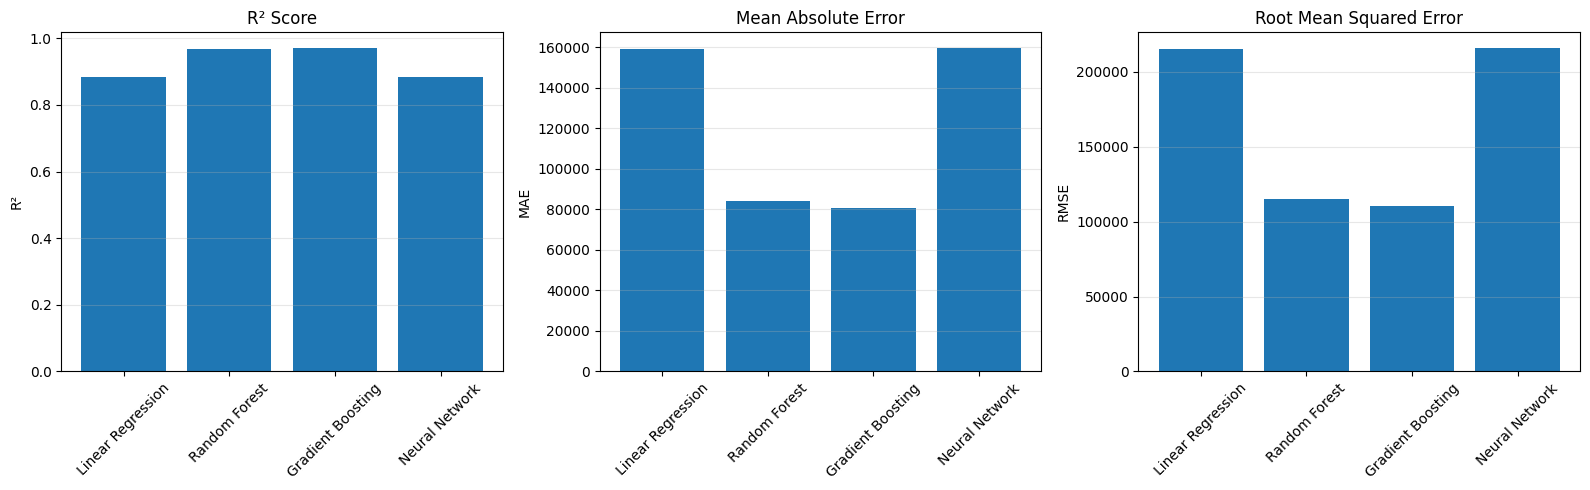

In [ ]:
# Visualize the results

results_df = pd.DataFrame(results)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# R²: higher is better
axes[0].bar(results_df["Model"], results_df["R²"])
axes[0].set_title("R² Score")
axes[0].set_ylabel("R²")

# MAE: lower is better
axes[1].bar(results_df["Model"], results_df["MAE"])
axes[1].set_title("Mean Absolute Error")
axes[1].set_ylabel("MAE")

# RMSE: lower is better
axes[2].bar(results_df["Model"], results_df["RMSE"])
axes[2].set_title("Root Mean Squared Error")
axes[2].set_ylabel("RMSE")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()